# Classification d’images : évaluer un modèle

**Objectif :** entraîner une régression logistique sur de vraies images de chiffres et mesurer accuracy, précision, rappel et F1. Jeu `digits` inclus dans scikit-learn : 1 797 images 8 × 8, dix classes. CPU, aucune collecte externe. La simplicité du modèle permet de concentrer l’explication sur l’évaluation.


In [6]:
# Cloner le dépôt GitHub
!git clone https://github.com/Et-taky/metric_evaluation_IA_avancee.git

fatal: destination path 'metric_evaluation_IA_avancee' already exists and is not an empty directory.


In [7]:

# !pip -q install -r requirements.txt


In [8]:
from pathlib import Path
import sys
import json
import matplotlib.pyplot as plt
import pandas as pd

# Définir la racine du projet cloné
ROOT = Path("/content/metric_evaluation_IA_avancee")

# Vérifier la structure
assert (ROOT / "src").exists(), "Le dossier src est introuvable"

# Ajouter le projet au Python path
sys.path.insert(0, str(ROOT))

# Créer le dossier results s'il n'existe pas
(ROOT / "results").mkdir(exist_ok=True)

print("Projet chargé avec succès :", ROOT)
print("Dossiers disponibles :", [p.name for p in ROOT.iterdir()])

Projet chargé avec succès : /content/metric_evaluation_IA_avancee
Dossiers disponibles : ['presentations', 'data', '.git', '.gitignore', 'src', 'requirements.txt', 'scripts', 'README.md', 'notebooks', 'results']


## 1. Séparer les données avant tout apprentissage
Le test contient 25 % des exemples. Le découpage stratifié conserve approximativement la proportion des chiffres. Aucune sélection de modèle ne sera faite avec ce test.


Entraînement : 1347 ; test : 450


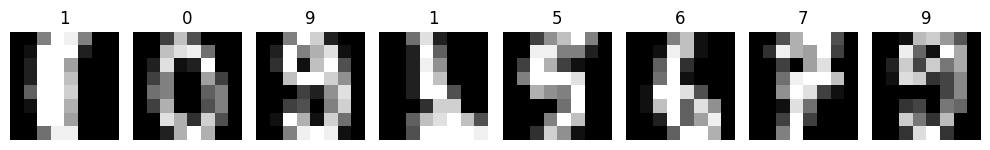

In [9]:
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score,classification_report,confusion_matrix,ConfusionMatrixDisplay
X,y=load_digits(return_X_y=True)
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.25,stratify=y,random_state=42)
print("Entraînement :",len(y_train),"; test :",len(y_test))
fig,axes=plt.subplots(1,8,figsize=(10,2))
for ax,x,label in zip(axes,X_test[:8],y_test[:8]):
    ax.imshow(x.reshape(8,8),cmap="gray"); ax.set_title(str(label)); ax.axis("off")
plt.tight_layout(); plt.savefig(ROOT/"results/digits.png",dpi=150); plt.show()


## 2. Apprendre uniquement sur l’entraînement
Le scaler est dans la pipeline : ses moyennes et écarts-types sont appris sur l’entraînement. La référence naïve prédit toujours la classe la plus fréquente ; elle aide à interpréter le gain du modèle.


In [10]:
model=make_pipeline(StandardScaler(),LogisticRegression(max_iter=2000,random_state=42))
model.fit(X_train,y_train)
pred=model.predict(X_test)
baseline=DummyClassifier(strategy="most_frequent").fit(X_train,y_train)
print("Accuracy modèle :",round(accuracy_score(y_test,pred),4))
print("Accuracy référence naïve :",round(baseline.score(X_test,y_test),4))


Accuracy modèle : 0.9778
Accuracy référence naïve : 0.1022


## 3. Calculer les métriques par classe
Pour un chiffre donné, les autres chiffres forment la classe négative : précision = VP/(VP+FP), rappel = VP/(VP+FN), F1 = 2PR/(P+R). Accuracy = bonnes prédictions / effectif total. Macro-F1 = moyenne des F1 des dix chiffres ; weighted-F1 pondère par le support.


VP : exemples correctement reconnus dans la classe ; FP : autres chiffres annoncés à tort comme appartenant à cette classe ; FN : vrais exemples de la classe qui ont été manqués.


In [11]:
report=classification_report(y_test,pred,output_dict=True,zero_division=0)
print(classification_report(y_test,pred,digits=3,zero_division=0))
summary={"accuracy":accuracy_score(y_test,pred),"macro_f1":report["macro avg"]["f1-score"],
         "weighted_f1":report["weighted avg"]["f1-score"],"n_test":len(y_test)}
(ROOT/"results/classification_scores.json").write_text(json.dumps(summary,indent=2))
pd.DataFrame(report).T.to_csv(ROOT/"results/classification_report.csv")


              precision    recall  f1-score   support

           0      1.000     1.000     1.000        45
           1      0.935     0.935     0.935        46
           2      1.000     1.000     1.000        44
           3      1.000     1.000     1.000        46
           4      0.978     1.000     0.989        45
           5      1.000     0.978     0.989        46
           6      1.000     0.978     0.989        45
           7      0.978     1.000     0.989        45
           8      0.909     0.930     0.920        43
           9      0.977     0.956     0.966        45

    accuracy                          0.978       450
   macro avg      0.978     0.978     0.978       450
weighted avg      0.978     0.978     0.978       450



## 4. Visualiser les confusions et contrôler le calcul
Lignes = vraies classes ; colonnes = classes prédites. La diagonale compte les bonnes réponses. Une cellule hors diagonale indique quel chiffre est confondu avec quel autre.


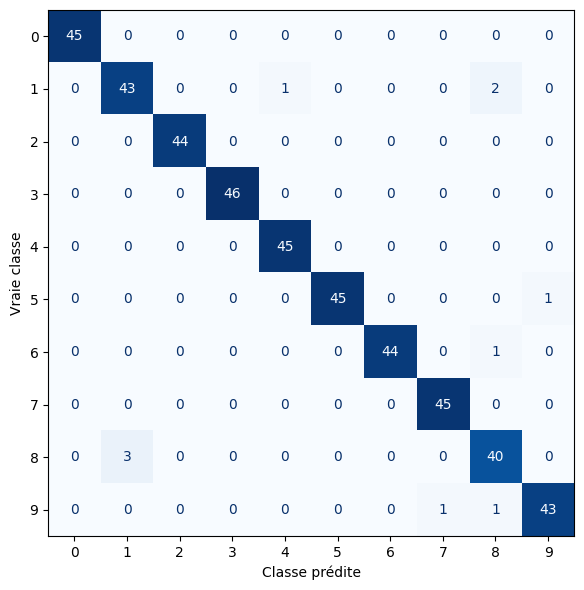

Chiffre 8 : VP, FP, FN = 40 4 3
Précision : 0.9090909090909091 ; rappel : 0.9302325581395349


In [12]:
cm=confusion_matrix(y_test,pred,labels=range(10))
fig,ax=plt.subplots(figsize=(7,6))
ConfusionMatrixDisplay(cm,display_labels=range(10)).plot(ax=ax,cmap="Blues",colorbar=False)
ax.set_xlabel("Classe prédite");ax.set_ylabel("Vraie classe")
plt.tight_layout();plt.savefig(ROOT/"results/confusion.png",dpi=160);plt.show()
assert abs(cm.trace()/cm.sum()-summary["accuracy"])<1e-12
chiffre=8
vp=cm[chiffre,chiffre];fp=cm[:,chiffre].sum()-vp;fn=cm[chiffre,:].sum()-vp
print("Chiffre 8 : VP, FP, FN =",vp,fp,fn)
print("Précision :",vp/(vp+fp),"; rappel :",vp/(vp+fn))


## 5. Interpréter sans généraliser trop vite
Une bonne accuracy globale peut masquer une classe faible : consulter son rappel et son F1. Le test reste indépendant de l’entraînement, mais ce petit jeu ne représente pas toutes les écritures manuscrites. Les scores sont des estimations sur ce découpage. Les métriques ROC-AUC et log-loss sont utiles pour les scores probabilistes, mais ne sont pas nécessaires pour expliquer ce cas multiclasse.
